In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:
# pip install tensorflow transformers safetensors huggingface_hub datasets matplotlib
import glob, os, math
import numpy as np
import tensorflow as tf
from huggingface_hub import snapshot_download
from safetensors.tensorflow import load_file
from transformers import AutoConfig, AutoTokenizer

MODEL = "TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T"  # debug model
# MODEL = "meta-llama/Llama-2-7b-hf"   # final run (gated: huggingface-cli login first)
DTYPE = tf.float16 if tf.config.list_physical_devices("GPU") else tf.float32

# download only the files we need
path = snapshot_download(MODEL, allow_patterns=["*.safetensors", "*.json", "tokenizer.model"])
cfg = AutoConfig.from_pretrained(path)      # architecture numbers (layers, heads, ...)
tok = AutoTokenizer.from_pretrained(path)   # text <-> token ids

# read weights into a dict:  "model.layers.0.self_attn.q_proj.weight" -> tf.Tensor
W = {}
for f in sorted(glob.glob(os.path.join(path, "*.safetensors"))):  # big models are sharded
    for name, tensor in load_file(f).items():
        W[name] = tf.cast(tensor, DTYPE)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

I0000 00:00:1791575361.892960      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791575361.897562      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [5]:
print(cfg.num_hidden_layers, cfg.num_attention_heads, cfg.num_key_value_heads, cfg.hidden_size)
print(W["model.layers.0.self_attn.q_proj.weight"].shape)
print(W["model.layers.0.self_attn.k_proj.weight"].shape)

22 32 4 2048
(2048, 2048)
(256, 2048)


In [ ]:
# For TinyLlama, I expect 22 32 4 2048, then (2048, 2048) and (256, 2048). Keys are smaller than queries because TinyLlama uses grouped-query attention (4 KV heads shared by 32 query heads). Llama-2-7B has 32 KV heads, so there the shapes are equal.

In [ ]:
#Loading one long book from the PG-29 dataset

In [7]:
from datasets import load_dataset

ds = load_dataset("emozilla/pg19-test", split="test")
print(ds)                      # check the column names and number of books
print(ds.column_names)

README.md:   0%|          | 0.00/473 [00:00<?, ?B/s]

data/test-00000-of-00001-29a571947c0b5cc(…): reconstructing file:   0%|          |  0.00B / 24.9MB            

data/test-00000-of-00001-29a571947c0b5cc(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

Dataset({
    features: ['short_book_title', 'publication_date', 'url', 'text'],
    num_rows: 100
})
['short_book_title', 'publication_date', 'url', 'text']


In [8]:
book = ds[0]["text"]           # one full book, a single very long string
print(len(book), "characters")
print(book[:300])

ids = tok(book, return_tensors="np").input_ids.astype(np.int32)   # shape [1, N]
print("total tokens in this book:", ids.shape[1])

ids = ids[:, :6000]            # start small for debugging; later use 20_000-65_000

249431 characters
ST. PAUL***


E-text prepared by Josephine Paolucci and the Project Gutenberg Online
Distributed Proofreading Team



REMINISCENCES OF PIONEER DAYS IN ST. PAUL

A Collection of Articles Written for and Published in the Daily
Pioneer Press.

By FRANK MOORE






NEWSPAPER STRUGGLES OF PIONEER DAYS.


total tokens in this book: 65134


In [ ]:
#Because I am using tensorflow, and HF doesn't has  TFllama, hence we just download and cache the weights and perform forward pass ourselves

In [9]:
n_layers = cfg.num_hidden_layers
n_heads  = cfg.num_attention_heads
n_kv     = getattr(cfg, "num_key_value_heads", None) or n_heads   # GQA: fewer KV heads
head_dim = cfg.hidden_size // n_heads
eps      = cfg.rms_norm_eps
theta    = getattr(cfg, "rope_theta", 10000.0)                    # RoPE base frequency
lm_head  = W.get("lm_head.weight", W["model.embed_tokens.weight"])  # tied-weights fallback

print(n_layers, n_heads, n_kv, head_dim, theta)   # TinyLlama: 22 32 4 64 10000.0

22 32 4 64 10000.0


In [10]:
def lin(x, name):
    # HF stores weights as [out_features, in_features], so we multiply by W^T
    return tf.matmul(x, W[name], transpose_b=True)

def rms_norm(x, name):
    xf = tf.cast(x, tf.float32)                                    # do the math in fp32
    xf = xf * tf.math.rsqrt(tf.reduce_mean(tf.square(xf), -1, keepdims=True) + eps)
    return W[name] * tf.cast(xf, x.dtype)                          # learned per-channel scale

In [11]:
def rotate_half(x):
    x1, x2 = tf.split(x, 2, axis=-1)          # first half and second half of head_dim
    return tf.concat([-x2, x1], axis=-1)

class Rope:
    def __init__(self, head_dim, max_pos, theta):
        # one frequency per pair of dimensions: theta^(-2i/head_dim)
        inv_freq = 1.0 / (theta ** (tf.range(0, head_dim, 2, dtype=tf.float32) / head_dim))
        t = tf.range(max_pos, dtype=tf.float32)                    # positions 0..max_pos-1
        freqs = tf.einsum("i,j->ij", t, inv_freq)                  # angle = position * freq
        emb = tf.concat([freqs, freqs], axis=-1)                   # [max_pos, head_dim]
        self.cos, self.sin = tf.cos(emb), tf.sin(emb)              # lookup tables (fp32)

    def apply(self, x, positions):
        # x: [B, heads, T, head_dim]    positions: int tensor [T]
        cos = tf.cast(tf.gather(self.cos, positions), x.dtype)[None, None]   # [1,1,T,hd]
        sin = tf.cast(tf.gather(self.sin, positions), x.dtype)[None, None]
        return x * cos + rotate_half(x) * sin

In [ ]:
# tf.split(x, 2, axis=-1) cuts the last axis (head_dim = 64) into two halves: x1 has numbers 0–31, x2 has numbers 32–63.
# [-x2, x1] returns the vector with the halves swapped and the new first half negated.

# This is a helper for the rotation. A 2D point (a, b) rotated by angle θ becomes:

# a' = a·cosθ − b·sinθ
# b' = b·cosθ + a·sinθ

# If x = [x1, x2], then x*cos + rotate_half(x)*sin gives:

# first half: x1·cos + (−x2)·sin = x1·cos − x2·sin
# second half: x2·cos + x1·sin

# So these two lines are exactly the 2D rotation formula, applied to all 32 pairs at once.

In [12]:
rope = Rope(head_dim, 4096, theta)
q = tf.random.normal([1, 1, 1, head_dim])
k = tf.random.normal([1, 1, 1, head_dim])

def score(i, j):   # query at position i, key at position j
    qi = rope.apply(q, tf.constant([i]))
    kj = rope.apply(k, tf.constant([j]))
    return float(tf.reduce_sum(qi * kj))

print(score(10, 3),    score(1010, 1003), score(3000, 2993))  # all distance 7 -> same
print(score(10, 3),    score(10, 5))                           # distance 7 vs 5 -> different

12.177755355834961 12.177659034729004 12.177852630615234
12.177755355834961 4.375241279602051


In [ ]:
# Remaining Helpers

In [14]:
def split_heads(t, n):                  # [1, T, n*head_dim] -> [1, n, T, head_dim]
    T = t.shape[1]
    return tf.transpose(tf.reshape(t, [1, T, n, head_dim]), [0, 2, 1, 3])

def qkv(x, i):                          # project one layer's input into Q, K, V
    p = f"model.layers.{i}.self_attn."
    q = split_heads(lin(x, p + "q_proj.weight"), n_heads)
    k = split_heads(lin(x, p + "k_proj.weight"), n_kv)
    v = split_heads(lin(x, p + "v_proj.weight"), n_kv)
    return q, k, v

def repeat_kv(t):                       # GQA: each KV head serves n_heads/n_kv query heads
    rep = n_heads // n_kv
    return t if rep == 1 else tf.repeat(t, rep, axis=1)

def attn_out_and_mlp(h, attn_out, i):
    p = f"model.layers.{i}."
    T = h.shape[1]
    a = tf.reshape(tf.transpose(attn_out, [0, 2, 1, 3]), [1, T, -1])  # merge heads back
    h = h + lin(a, p + "self_attn.o_proj.weight")                     # output projection + residual
    x = rms_norm(h, p + "post_attention_layernorm.weight")
    gate = lin(x, p + "mlp.gate_proj.weight")
    up   = lin(x, p + "mlp.up_proj.weight")
    return h + lin(tf.nn.silu(gate) * up, p + "mlp.down_proj.weight")  # gated MLP + residual

def to_logits(h):
    h = rms_norm(h, "model.norm.weight")
    return tf.cast(tf.matmul(h, lm_head, transpose_b=True), tf.float32)  # [1, T, vocab]

In [15]:
def forward_full(ids, return_attn=False):
    T = ids.shape[1]
    rope = Rope(head_dim, T, theta)
    pos = tf.range(T)
    causal = tf.linalg.band_part(tf.ones((T, T)), -1, 0)     # lower-triangular mask
    h = tf.gather(W["model.embed_tokens.weight"], tf.constant(ids))   # [1, T, hidden]
    maps, mass0 = [], []
    for i in range(n_layers):
        x = rms_norm(h, f"model.layers.{i}.input_layernorm.weight")
        q, k, v = qkv(x, i)
        q, k = rope.apply(q, pos), rope.apply(k, pos)         # RoPE on Q and K only
        k, v = repeat_kv(k), repeat_kv(v)
        s = tf.cast(tf.matmul(q, k, transpose_b=True), tf.float32) / math.sqrt(head_dim)
        s += (1.0 - causal) * -1e9                            # block attention to the future
        p = tf.nn.softmax(s, axis=-1)                         # [1, H, T, T]
        if return_attn:
            maps.append(tf.reduce_mean(p[0], 0).numpy())      # average over heads -> [T, T]
            mass0.append(float(tf.reduce_mean(p[0, :, 8:, 0])))  # attention on token 0
        h = attn_out_and_mlp(h, tf.matmul(tf.cast(p, v.dtype), v), i)
    logits = to_logits(h)[0]                                  # [T, vocab]
    return (logits, maps, mass0) if return_attn else logits

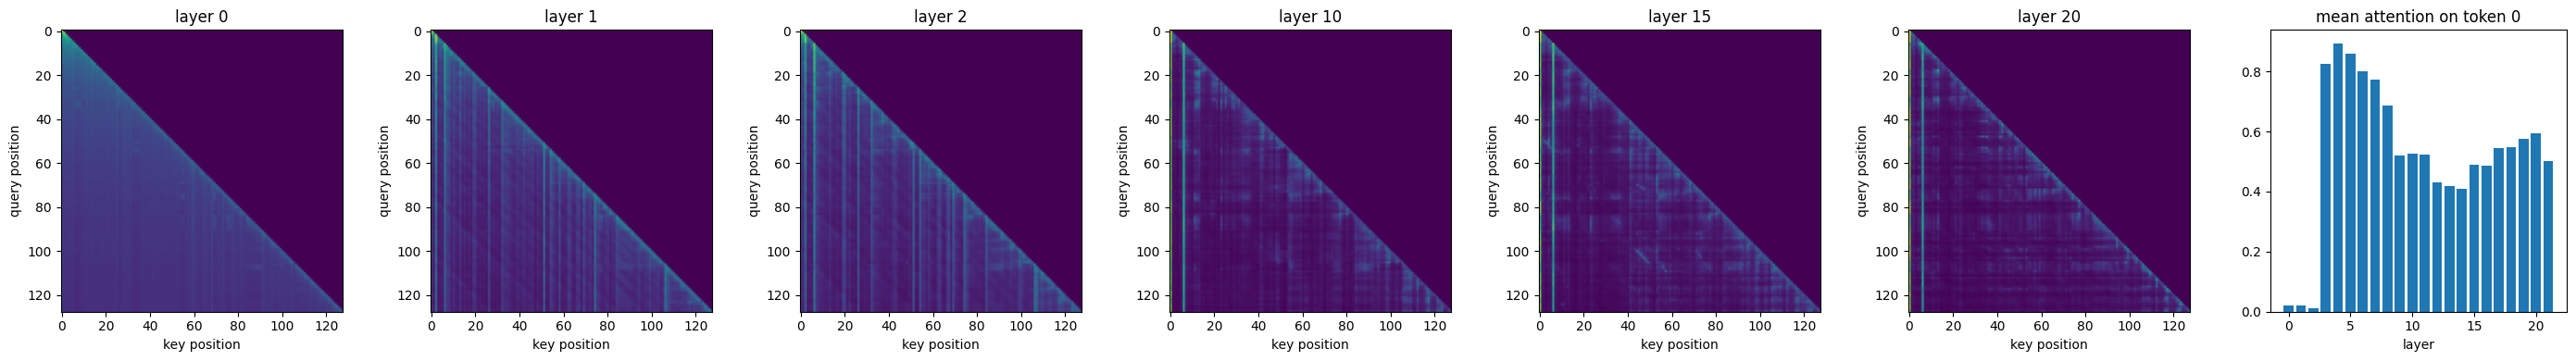

In [16]:
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

_, maps, mass0 = forward_full(ids[:, :128], return_attn=True)

show = [l for l in (0, 1, 2, 10, 15, 20) if l < n_layers]
fig, axes = plt.subplots(1, len(show) + 1, figsize=(4 * (len(show) + 1), 4))
for ax, l in zip(axes[:-1], show):
    ax.imshow(maps[l], cmap="viridis", norm=PowerNorm(0.4))
    ax.set_title(f"layer {l}"); ax.set_xlabel("key position"); ax.set_ylabel("query position")
axes[-1].bar(range(n_layers), mass0)
axes[-1].set_title("mean attention on token 0"); axes[-1].set_xlabel("layer")
plt.tight_layout(); plt.savefig("attention_sinks.png", dpi=150); plt.show()

In [18]:
class RollingKVCache:
    """
    Per-layer cache of UN-ROTATED keys and values, each [1, kv_heads, T, head_dim].
      n_sink   : first tokens that are never evicted (0 => plain window attention)
      n_recent : size of the rolling window          (None => keep everything = dense)
    Total cache size = n_sink + n_recent.
    """
    def __init__(self, n_sink, n_recent):
        self.n_sink, self.n_recent = n_sink, n_recent
        self.k = [None] * n_layers
        self.v = [None] * n_layers

    def update(self, layer, k_new, v_new):
        if self.k[layer] is None:
            k, v = k_new, v_new
        else:
            k = tf.concat([self.k[layer], k_new], axis=2)     # append the new token
            v = tf.concat([self.v[layer], v_new], axis=2)
        if self.n_recent is not None and k.shape[2] > self.n_sink + self.n_recent:
            # evict the middle: keep first n_sink tokens + last n_recent tokens
            k = tf.concat([k[:, :, :self.n_sink], k[:, :, -self.n_recent:]], axis=2)
            v = tf.concat([v[:, :, :self.n_sink], v[:, :, -self.n_recent:]], axis=2)
        self.k[layer], self.v[layer] = k, v
        return k, v

In [19]:
c = RollingKVCache(2, 3)
for t in range(8):
    k, v = c.update(0, tf.fill([1, n_kv, 1, head_dim], float(t)), tf.zeros([1, n_kv, 1, head_dim]))
print(k.shape[2])                              # 5  (= 2 sinks + 3 recent)
print(k[0, 0, :, 0].numpy())                   # [0. 1. 5. 6. 7.]  -> tokens 0,1 + the last 3

5
[0. 1. 5. 6. 7.]


In [20]:
def step(rope, token_id, cache):
    """token_id: int32 array [1,1]. Returns next-token logits, shape [vocab]."""
    h = tf.gather(W["model.embed_tokens.weight"], tf.constant(token_id))   # [1, 1, hidden]
    for i in range(n_layers):
        x = rms_norm(h, f"model.layers.{i}.input_layernorm.weight")
        q, k, v = qkv(x, i)                       # all for this single new token
        K, V = cache.update(i, k, v)              # un-rotated keys, evicted if needed
        T = K.shape[2]
        pos = tf.range(T)                         # cache SLOTS 0..T-1, not original positions
        K = rope.apply(K, pos)                    # re-rotate ALL cached keys by slot
        q = rope.apply(q, pos[-1:])               # query sits at the last slot
        K, V = repeat_kv(K), repeat_kv(V)
        s = tf.cast(tf.matmul(q, K, transpose_b=True), tf.float32) / math.sqrt(head_dim)
        p = tf.nn.softmax(s, axis=-1)             # [1, H, 1, T]; no mask: query is the last token
        h = attn_out_and_mlp(h, tf.matmul(tf.cast(p, V.dtype), V), i)
    return to_logits(h)[0, -1]                    # [vocab]

In [21]:
n = 48
ref = forward_full(ids[:, :n])                                  # one-shot reference [n, vocab]
rope = Rope(head_dim, n, theta)
cache = RollingKVCache(0, None)                                 # dense: no eviction
mine = tf.stack([step(rope, ids[:, t:t+1], cache) for t in range(n)])
print("max |logit diff|:", float(tf.reduce_max(tf.abs(ref - mine))))

max |logit diff|: 0.0546875


In [ ]:
# What this test is for

# You have two different code paths that should compute the same thing:

# forward_full: processes all 48 tokens at once (one big attention matrix with a causal mask). It has no cache.
# step: processes one token at a time, reading earlier tokens’ K and V from the RollingKVCache.

# If we use the cache with no eviction, both paths must give the same logits for every token. Any real difference means a bug in the cache, in the RoPE slot positions, or in the attention logic of step.

In [ ]:
# Block 7: Perplexity: dense vs window vs StreamingLLM

In [22]:
def eval_nll(ids, n_sink, n_recent, log_every=1000):
    rope = Rope(head_dim, ids.shape[1] + 1, theta)
    cache = RollingKVCache(n_sink, n_recent)
    nlls = []
    for t in range(ids.shape[1] - 1):
        logits = step(rope, ids[:, t:t+1], cache)               # predict token t+1
        nll = tf.nn.sparse_softmax_cross_entropy_with_logits(
            labels=ids[0, t+1:t+2], logits=logits[None])
        nlls.append(float(nll[0]))
        if (t + 1) % log_every == 0:
            print(f"  {t+1} tokens, running ppl = {math.exp(np.mean(nlls)):.2f}")
    return np.array(nlls)

BUDGET, PRETRAIN, N_SINK = 1024, 2048, 4        # TinyLlama; for Llama-2: PRETRAIN=4096

configs = {
    "dense (full cache)":                        (0, None),
    f"window attention ({BUDGET})":              (0, BUDGET),
    f"StreamingLLM ({N_SINK}+{BUDGET-N_SINK})":  (N_SINK, BUDGET - N_SINK),
}
results = {}
for name, (s, r) in configs.items():
    print(name)
    results[name] = eval_nll(ids, s, r)
    print(f"  => final perplexity: {math.exp(results[name].mean()):.2f}")

dense (full cache)
  1000 tokens, running ppl = 7.59
  2000 tokens, running ppl = 7.83
  3000 tokens, running ppl = 51.23
  4000 tokens, running ppl = 239.30
  5000 tokens, running ppl = 455.52
  => final perplexity: 663.96
window attention (1024)
  1000 tokens, running ppl = 7.59
  2000 tokens, running ppl = 42.74
  3000 tokens, running ppl = 99.65
  4000 tokens, running ppl = 139.28
  5000 tokens, running ppl = 148.84
  => final perplexity: 164.43
StreamingLLM (4+1020)
  1000 tokens, running ppl = 7.59
  2000 tokens, running ppl = 7.85
  3000 tokens, running ppl = 8.06
  4000 tokens, running ppl = 8.21
  5000 tokens, running ppl = 8.35
  => final perplexity: 8.39


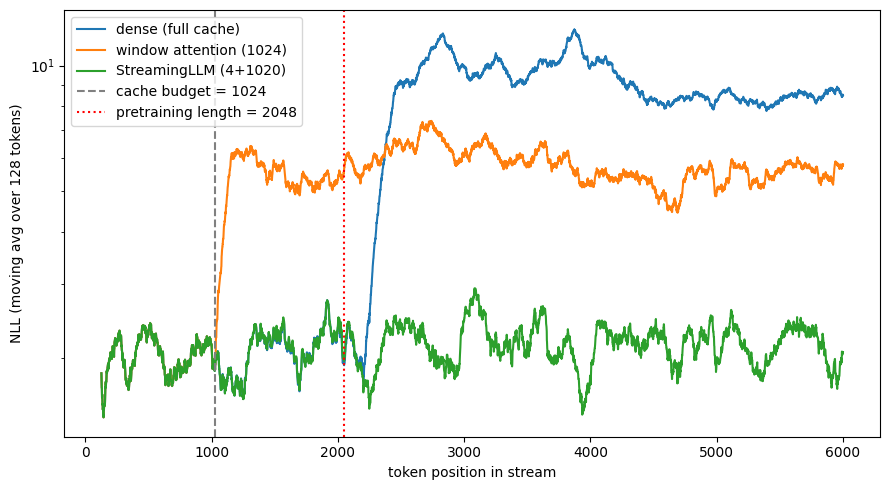

dense (full cache)                  ppl =     663.96
window attention (1024)             ppl =     164.43
StreamingLLM (4+1020)               ppl =       8.39


In [23]:
smooth = 128
fig, ax = plt.subplots(figsize=(9, 5))
for name, nll in results.items():
    sm = np.convolve(nll, np.ones(smooth) / smooth, mode="valid")   # moving-average NLL
    ax.plot(np.arange(len(sm)) + smooth, sm, label=name)
ax.axvline(BUDGET, ls="--", c="gray", label=f"cache budget = {BUDGET}")
ax.axvline(PRETRAIN, ls=":", c="red", label=f"pretraining length = {PRETRAIN}")
ax.set_xlabel("token position in stream")
ax.set_ylabel(f"NLL (moving avg over {smooth} tokens)")
ax.set_yscale("log")
ax.legend(); plt.tight_layout(); plt.savefig("ppl_comparison.png", dpi=150); plt.show()

# summary table
for name, nll in results.items():
    print(f"{name:35s} ppl = {math.exp(nll.mean()):10.2f}")

Perplexity Comparison in The 3 methods

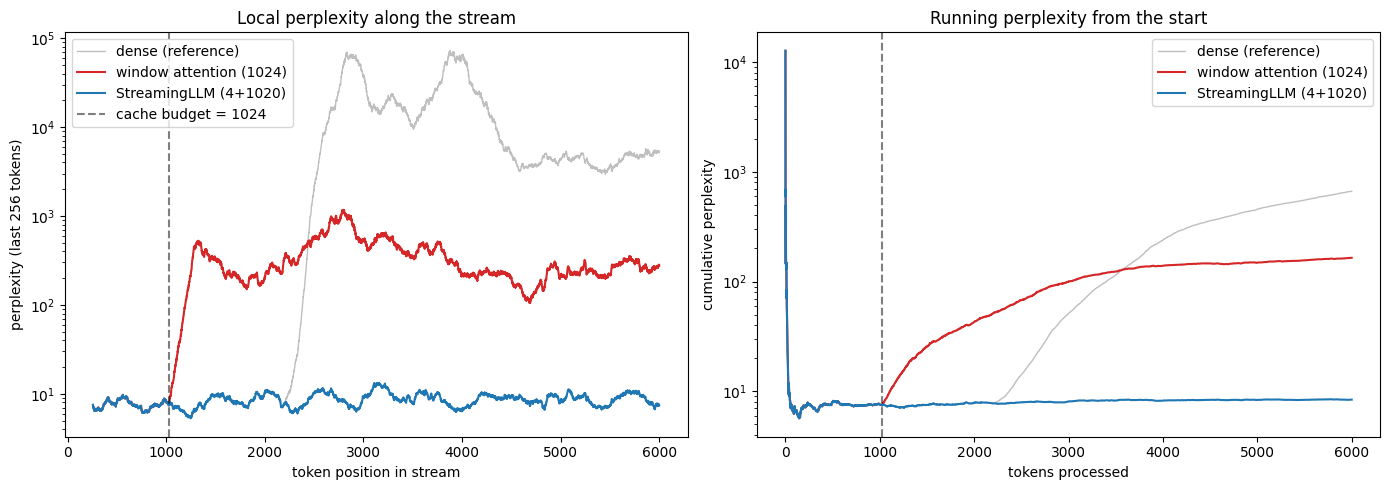

In [24]:
def windowed_ppl(nll, win=256):
    # exp of the moving-average NLL: "perplexity of the last `win` tokens" at each position
    sm = np.convolve(nll, np.ones(win) / win, mode="valid")
    return np.arange(len(sm)) + win, np.exp(sm)

def running_ppl(nll):
    # cumulative perplexity from token 0 up to each position
    return np.exp(np.cumsum(nll) / np.arange(1, len(nll) + 1))

win_key  = f"window attention ({BUDGET})"
strm_key = f"StreamingLLM ({N_SINK}+{BUDGET - N_SINK})"
dense_key = "dense (full cache)"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left: windowed perplexity
ax = axes[0]
x, y = windowed_ppl(results[dense_key]);  ax.plot(x, y, c="gray", alpha=0.5, lw=1, label="dense (reference)")
x, y = windowed_ppl(results[win_key]);    ax.plot(x, y, c="tab:red",  label=win_key)
x, y = windowed_ppl(results[strm_key]);   ax.plot(x, y, c="tab:blue", label=strm_key)
ax.axvline(BUDGET, ls="--", c="k", alpha=0.5, label=f"cache budget = {BUDGET}")
ax.set_yscale("log")
ax.set_xlabel("token position in stream"); ax.set_ylabel("perplexity (last 256 tokens)")
ax.set_title("Local perplexity along the stream"); ax.legend()

# right: cumulative perplexity
ax = axes[1]
ax.plot(running_ppl(results[dense_key]), c="gray", alpha=0.5, lw=1, label="dense (reference)")
ax.plot(running_ppl(results[win_key]),   c="tab:red",  label=win_key)
ax.plot(running_ppl(results[strm_key]),  c="tab:blue", label=strm_key)
ax.axvline(BUDGET, ls="--", c="k", alpha=0.5)
ax.set_yscale("log")
ax.set_xlabel("tokens processed"); ax.set_ylabel("cumulative perplexity")
ax.set_title("Running perplexity from the start"); ax.legend()

plt.tight_layout(); plt.savefig("ppl_window_vs_streaming.png", dpi=150); plt.show()

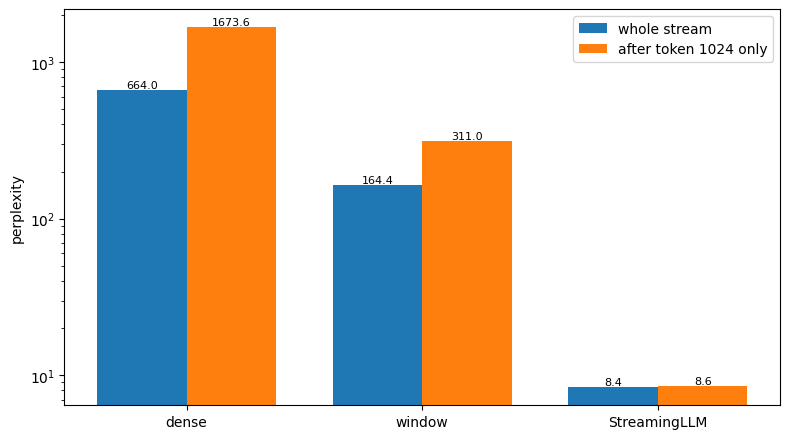

In [25]:
names  = [dense_key, win_key, strm_key]
finals = [math.exp(results[n].mean()) for n in names]
# also after the budget only (where eviction is active)
after  = [math.exp(results[n][BUDGET:].mean()) for n in names]

xs = np.arange(len(names)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(xs - w/2, finals, w, label="whole stream")
ax.bar(xs + w/2, after,  w, label=f"after token {BUDGET} only")
ax.set_xticks(xs); ax.set_xticklabels(["dense", "window", "StreamingLLM"])
ax.set_yscale("log"); ax.set_ylabel("perplexity"); ax.legend()
for i, (a, b) in enumerate(zip(finals, after)):
    ax.text(i - w/2, a, f"{a:.1f}", ha="center", va="bottom", fontsize=8)
    ax.text(i + w/2, b, f"{b:.1f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig("ppl_bars.png", dpi=150); plt.show()

Attention Score Final Plots

In [26]:
def step(rope, token_id, cache, record=None):
    h = tf.gather(W["model.embed_tokens.weight"], tf.constant(token_id))
    for i in range(n_layers):
        x = rms_norm(h, f"model.layers.{i}.input_layernorm.weight")
        q, k, v = qkv(x, i)
        K, V = cache.update(i, k, v)
        T = K.shape[2]
        pos = tf.range(T)
        K = rope.apply(K, pos)
        q = rope.apply(q, pos[-1:])
        K, V = repeat_kv(K), repeat_kv(V)
        s = tf.cast(tf.matmul(q, K, transpose_b=True), tf.float32) / math.sqrt(head_dim)
        p = tf.nn.softmax(s, axis=-1)                                  # [1, H, 1, T]
        if record is not None:                                         # NEW: save attention
            record[i].append(tf.reduce_mean(p[0, :, 0, :], axis=0).numpy())  # avg over heads -> [T]
        h = attn_out_and_mlp(h, tf.matmul(tf.cast(p, V.dtype), V), i)
    return to_logits(h)[0, -1]

In [27]:
B, S, N = 256, 4, 600          # small budget so the cache fills quickly: 1200 steps total

def collect(n_sink, n_recent, n_tokens=N):
    rope = Rope(head_dim, n_tokens + 1, theta)
    cache = RollingKVCache(n_sink, n_recent)
    rec = [[] for _ in range(n_layers)]            # rec[layer] = list of [T] attention vectors
    for t in range(n_tokens):
        step(rope, ids[:, t:t+1], cache, record=rec)
    return rec

rec_win = collect(0, B)            # window attention, cache size 256
rec_str = collect(S, B - S)        # StreamingLLM, 4 + 252 = 256

def to_matrix(rec_layer, B):       # rows = steps, columns = cache slots
    M = np.full((len(rec_layer), B), np.nan)
    for t, a in enumerate(rec_layer):
        M[t, :len(a)] = a
    return M

M_win = [to_matrix(r, B) for r in rec_win]
M_str = [to_matrix(r, B) for r in rec_str]

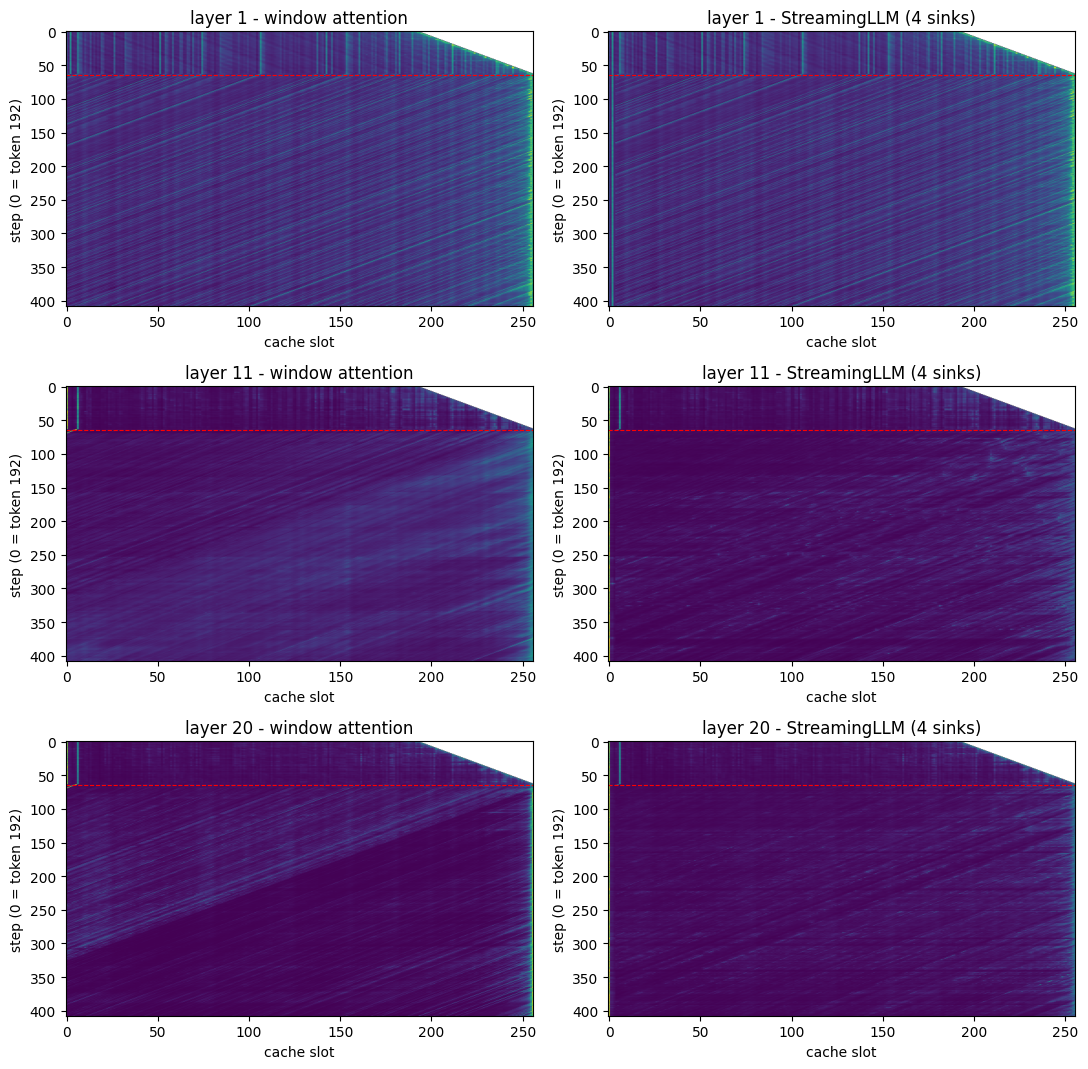

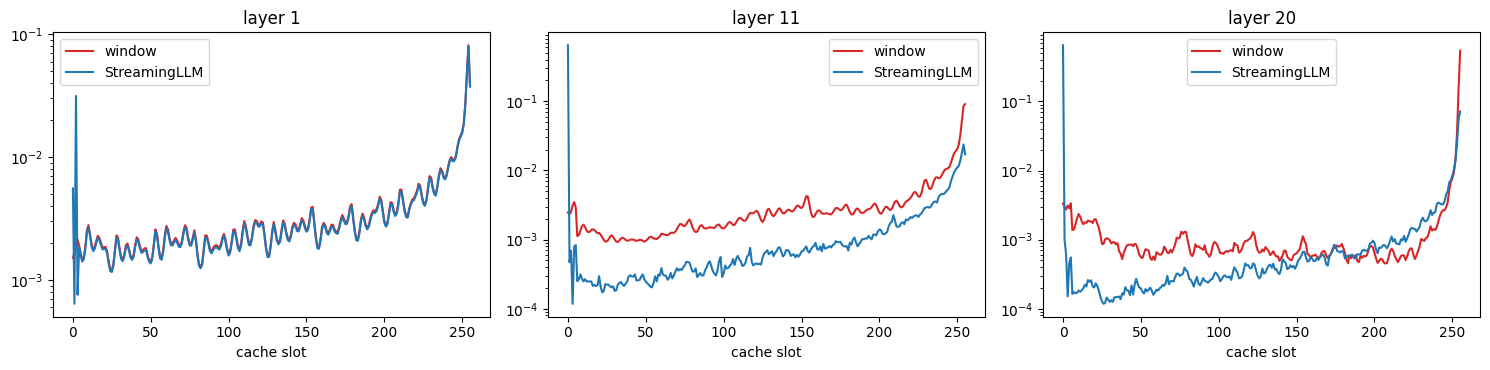

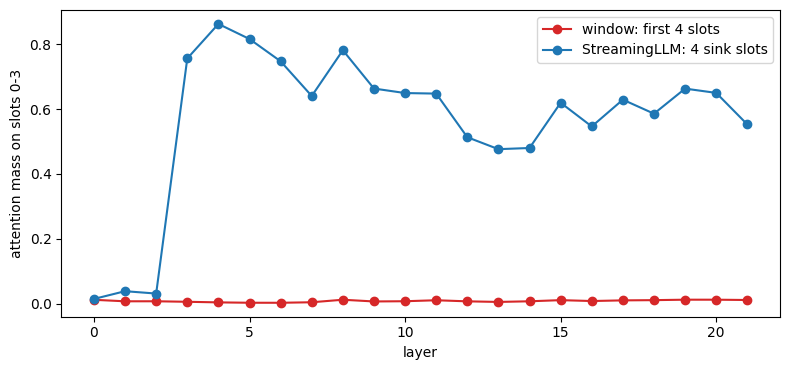

In [28]:
from matplotlib.colors import PowerNorm
show = [l for l in (1, n_layers // 2, n_layers - 2) if l < n_layers]

# (1) heatmaps: attention over cache slots, step by step
fig, axes = plt.subplots(len(show), 2, figsize=(11, 3.6 * len(show)))
for r, l in enumerate(show):
    for c, (M, title) in enumerate([(M_win[l], "window attention"), (M_str[l], f"StreamingLLM ({S} sinks)")]):
        ax = axes[r, c]
        im = ax.imshow(M[B - 64:], aspect="auto", cmap="viridis", norm=PowerNorm(0.4))
        ax.axhline(64, c="red", ls="--", lw=0.8)                    # step B: cache becomes full
        ax.set_title(f"layer {l} - {title}")
        ax.set_xlabel("cache slot"); ax.set_ylabel(f"step (0 = token {B-64})")
plt.tight_layout(); plt.savefig("attn_cache_slots.png", dpi=150); plt.show()

# (2) average attention per slot after the cache is full
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 3.8))
for ax, l in zip(np.atleast_1d(axes), show):
    ax.plot(np.nanmean(M_win[l][B:], axis=0), c="tab:red",  label="window")
    ax.plot(np.nanmean(M_str[l][B:], axis=0), c="tab:blue", label="StreamingLLM")
    ax.set_yscale("log"); ax.set_title(f"layer {l}"); ax.set_xlabel("cache slot"); ax.legend()
plt.tight_layout(); plt.savefig("attn_per_slot.png", dpi=150); plt.show()

# (3) attention mass on the first 4 cache slots, per layer
mass_win = [np.nanmean(M[B:, :S].sum(1)) for M in M_win]
mass_str = [np.nanmean(M[B:, :S].sum(1)) for M in M_str]
plt.figure(figsize=(8, 3.8))
plt.plot(mass_win, "o-", c="tab:red",  label="window: first 4 slots")
plt.plot(mass_str, "o-", c="tab:blue", label="StreamingLLM: 4 sink slots")
plt.xlabel("layer"); plt.ylabel("attention mass on slots 0-3"); plt.legend()
plt.tight_layout(); plt.savefig("sink_mass_by_layer.png", dpi=150); plt.show()